In [1]:
import numpy as np
import matplotlib.pyplot as plt
from utils import (get_data, calc_hist, weighted_avg_and_std)

In [6]:
EMB_FILE = '/gpfs01/star/pwg/youqi/run12/final_0628/results_20235003/matched/all050124_rc_notrueptcons.root'
COLUMNS  = ['pt', 'b', 'w', 'y1', 'y2', 'phi1', 'phi2',
            'pts', 'bs', 'ws', 'y1s', 'y2s', 'phi1s', 'phi2s', 'nefs']
PT_EDGES   = [15, 20, 25, 30, 40]
PT_CENTERS = [17.5, 22.5, 27.5, 35]
PT_XERR    = [2.5, 2.5, 2.5, 5]

In [7]:
df = get_data(COLUMNS, EMB_FILE, 'MatchedTree').query('w < 1 and pts > 15 and bs != -9 and nefs < 0.9').copy()

In [8]:
def delta_phi(a, b):
    diff = np.abs(a - b)
    return np.minimum(diff, 2 * np.pi - diff)

df['distance1'] = np.sqrt(delta_phi(df['phi1'].values, df['phi1s'].values)**2
                          + (df['y1'].values - df['y1s'].values)**2)
df['distance2'] = np.sqrt(delta_phi(df['phi2'].values, df['phi2s'].values)**2
                          + (df['y2'].values - df['y2s'].values)**2)

df_match = df.query('pt!=-9 and b!=-9 and distance1<0.02 and distance2<0.02').copy()
df_match['dpt_pt'] = (df_match['pts'] - df_match['pt']) / df_match['pt']

In [9]:
def weighted_err_on_mean(df_bins, query_str):
    result = []
    for df_bin in df_bins:
        df_sub = df_bin.query(query_str)
        w_array = np.unique(df_sub['w'])
        err2 = 0
        for w_i in w_array:
            variance = weighted_avg_and_std(df_sub['dpt_pt'], df_sub['w'])[1]**2 / df_sub[df_sub.w == w_i].shape[0]
            w = sum(df_sub[df_sub.w == w_i]['w']) / sum(df_sub['w'])
            err2 += w**2 * variance
        result.append(err2)
    return result

In [ ]:
df_match_pts_array = [df_match[(df_match.pts > PT_EDGES[i]) & (df_match.pts < PT_EDGES[i+1])]
                      for i in range(4)]

dpt_pt_array_os, sigma_dpt_pt_array_os = [], []
dpt_pt_array_ss, sigma_dpt_pt_array_ss = [], []
for i, df_bin in enumerate(df_match_pts_array):
    df_os = df_bin.query('bs==-1')
    df_ss = df_bin.query('bs==1')
    m_os, s_os = weighted_avg_and_std(df_os['dpt_pt'], df_os['w'])
    m_ss, s_ss = weighted_avg_and_std(df_ss['dpt_pt'], df_ss['w'])
    dpt_pt_array_os.append(m_os)
    sigma_dpt_pt_array_os.append(s_os)
    dpt_pt_array_ss.append(m_ss)
    sigma_dpt_pt_array_ss.append(s_ss)    
err_on_mean_os = weighted_err_on_mean(df_match_pts_array, 'b==-1')
err_on_mean_ss = weighted_err_on_mean(df_match_pts_array, 'b==1')

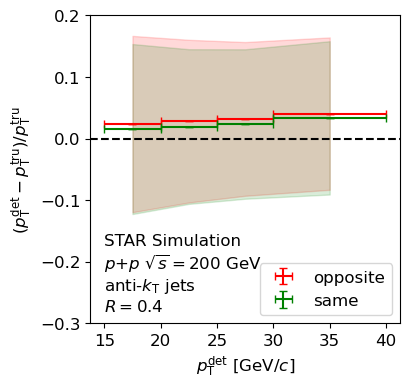

In [ ]:
plt.rcParams['font.size'] = 12
fig, ax = plt.subplots(figsize=(4, 4))
ax.errorbar(PT_CENTERS, dpt_pt_array_os, xerr=PT_XERR, yerr=err_on_mean_os, color='r', label='opposite', ls='none', capsize=3)
ax.errorbar(PT_CENTERS, dpt_pt_array_ss, xerr=PT_XERR, yerr=err_on_mean_ss, color='g', label='same', ls='none', capsize=3)
ax.fill_between(PT_CENTERS, np.array(dpt_pt_array_os) - np.array(sigma_dpt_pt_array_os),
                np.array(dpt_pt_array_os) + np.array(sigma_dpt_pt_array_os), color='r', alpha=0.15)
ax.fill_between(PT_CENTERS, np.array(dpt_pt_array_ss) - np.array(sigma_dpt_pt_array_ss),
                np.array(dpt_pt_array_ss) + np.array(sigma_dpt_pt_array_ss), color='g', alpha=0.15)
ax.axhline(0.0, color='k', linestyle='--')
ax.set_xlabel(r'$p_{\mathrm{T}}^{\mathrm{det}}$ [GeV$/c$]')
ax.set_ylabel(r'$(p_{\mathrm{T}}^{\mathrm{det}}-p_{\mathrm{T}}^{\mathrm{tru}})/p_{\mathrm{T}}^{\mathrm{tru}}$')
ax.text(15, -0.28, 'STAR Simulation\n$p$+$p$ $\\sqrt{s}=200$ GeV\nanti-$k_{\\mathrm{T}}$ jets\n$R=0.4$')
ax.set_ylim(-0.3, 0.2)
ax.legend(loc='lower right')

In [ ]:
df_match_pt_array = [df_match[(df_match.pt > PT_EDGES[i]) & (df_match.pt < PT_EDGES[i+1])]
                     for i in range(4)]

dpt_pt_array_os, sigma_dpt_pt_array_os = [], []
dpt_pt_array_ss, sigma_dpt_pt_array_ss = [], []
for i, df_bin in enumerate(df_match_pt_array):
    df_os = df_bin.query('bs==-1')
    df_ss = df_bin.query('bs==1')
    m_os, s_os = weighted_avg_and_std(df_os['dpt_pt'], df_os['w'])
    m_ss, s_ss = weighted_avg_and_std(df_ss['dpt_pt'], df_ss['w'])
    dpt_pt_array_os.append(m_os)
    sigma_dpt_pt_array_os.append(s_os)
    dpt_pt_array_ss.append(m_ss)
    sigma_dpt_pt_array_ss.append(s_ss)
err_on_mean_os = weighted_err_on_mean(df_match_pt_array, 'b==-1')
err_on_mean_ss = weighted_err_on_mean(df_match_pt_array, 'b==1')

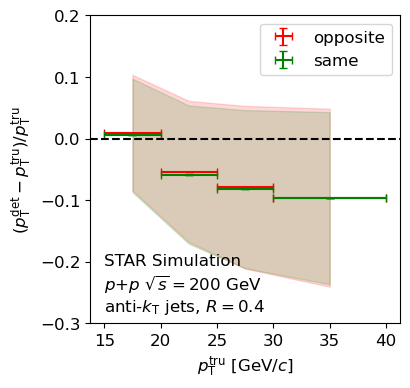

In [ ]:
fig, ax = plt.subplots(figsize=(4, 4))
ax.errorbar(PT_CENTERS, dpt_pt_array_os, xerr=PT_XERR, yerr=err_on_mean_os, color='r', label='opposite', ls='none', capsize=3)
ax.errorbar(PT_CENTERS, dpt_pt_array_ss, xerr=PT_XERR, yerr=err_on_mean_ss, color='g', label='same', ls='none', capsize=3)
ax.axhline(0.0, color='k', linestyle='--')
ax.fill_between(PT_CENTERS, np.array(dpt_pt_array_os) - np.array(sigma_dpt_pt_array_os),
                np.array(dpt_pt_array_os) + np.array(sigma_dpt_pt_array_os), color='r', alpha=0.15)
ax.fill_between(PT_CENTERS, np.array(dpt_pt_array_ss) - np.array(sigma_dpt_pt_array_ss),
                np.array(dpt_pt_array_ss) + np.array(sigma_dpt_pt_array_ss), color='g', alpha=0.15)
ax.set_xlabel(r'$p_{\mathrm{T}}^{\mathrm{tru}}$ [GeV$/c$]')
ax.set_ylabel(r'$(p_{\mathrm{T}}^{\mathrm{det}}-p_{\mathrm{T}}^{\mathrm{tru}})/p_{\mathrm{T}}^{\mathrm{tru}}$')
ax.text(15, -0.28, 'STAR Simulation\n$p$+$p$ $\\sqrt{s}=200$ GeV\nanti-$k_{\\mathrm{T}}$ jets, $R=0.4$')
ax.set_ylim(-0.3, 0.2)
ax.legend()